# GK - Phần thực hành (60 phút)
**Họ và tên:** Thái Anh Lạc  
**MSSV:** 089206000860  
**Mã lớp học phần:** 012012204103  
**Môn học:** Khai thác dữ liệu (Data Mining)

In [3]:
import pandas as pd
df = pd.read_csv('D0-apple_quality.csv')
# 1a.Kích thước và chiều của dữ liệu
print('Kich thuoc cua du lieu :',df.shape[0])
print('Chieu cua du lieu :',df.shape[1])

Kich thuoc cua du lieu : 4001
Chieu cua du lieu : 9


In [4]:
# 1b. Kiểu dữ liệu của các thuộc tính
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4001 entries, 0 to 4000
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   A_id         4000 non-null   float64
 1   Size         4000 non-null   float64
 2   Weight       4000 non-null   float64
 3   Sweetness    4000 non-null   float64
 4   Crunchiness  4000 non-null   float64
 5   Juiciness    4000 non-null   float64
 6   Ripeness     4000 non-null   float64
 7   Acidity      4001 non-null   str    
 8   Quality      4000 non-null   str    
dtypes: float64(7), str(2)
memory usage: 340.1 KB


In [5]:
# 1c. Số lượng thực thể của các giá trị nhãn
[print(f'Nhãn {i} : {j} thực thể') for i, j in df['Quality'].value_counts().items()]

Nhãn good : 2004 thực thể
Nhãn bad : 1996 thực thể


[None, None]

In [6]:
# 1d. Giá trị lớn nhất, bé nhất, và trung bình của các cột thuộc tính có giá trị số thực
df.describe()

,A_id,Size,Weight,Sweetness,Crunchiness,Juiciness,Ripeness
count,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000
mean,1999.500000,-0.503015,-0.989547,-0.470479,0.985478,0.512118,0.498277
std,1154.844867,1.928059,1.602507,1.943441,1.402757,1.930286,1.874427
min,0.000000,-7.151703,-7.149848,-6.894485,-6.055058,-5.961897,-5.864599
25%,999.750000,-1.816765,-2.011770,-1.738425,0.062764,-0.801286,-0.771677
50%,1999.500000,-0.513703,-0.984736,-0.504758,0.998249,0.534219,0.503445
75%,2999.250000,0.805526,0.030976,0.801922,1.894234,1.835976,1.766212
max,3999.000000,6.406367,5.790714,6.374916,7.619852,7.364403,7.237837


---
## Câu 2: Tiền xử lý dữ liệu và trực quan hóa

### 2.a. Xem xét bỏ những cột không có ý nghĩa dự đoán

**Giải thích chi tiết:**
- **Cột `A_id` (Apple ID):** Đây chỉ là mã số định danh duy nhất được gán ngẫu nhiên cho từng mẫu quả táo trong tập dữ liệu. Giá trị định danh này mang tính đại số thuần túy, hoàn toàn độc lập và không mang bất kỳ đặc tính sinh học hay quy luật tự nhiên nào liên quan đến chất lượng quả táo (`Quality`). Nếu giữ lại cột này, mô hình học máy có thể học các mối tương quan giả (spurious correlation) hoặc dẫn đến hiện tượng quá khớp (overfitting). Do đó, cột `A_id` cần được loại bỏ.

- **Dòng cuối cùng (Dòng lỗi):** Khi kiểm tra `df.info()`, dòng cuối cùng (index 4000) chứa chuỗi thông tin tác giả `"Created_by_Nidula_Elgiriyewithana"` tại cột `Acidity`, trong khi toàn bộ các trường khác đều là giá trị rỗng (`NaN`). Dòng này không phải là một quan sát thực tế và là nguyên nhân khiến cột `Acidity` bị nhận diện sai kiểu dữ liệu thành dạng chuỗi (`object`). Dòng này cần được loại bỏ khỏi dữ liệu.

In [ ]:
# 2.a. Loại bỏ dòng lỗi và xóa cột định danh A_id không có ý nghĩa dự đoán
df_clean = df.dropna().copy()
df_clean = df_clean.drop(columns=['A_id'])

print(f"Kích thước tập dữ liệu sau khi làm sạch: {df_clean.shape[0]} dòng, {df_clean.shape[1]} cột")
df_clean.head()

Kích thước tập dữ liệu sau khi làm sạch: 4000 dòng, 8 cột


,Size,Weight,Sweetness,Crunchiness,Juiciness,Ripeness,Acidity,Quality
0,-3.970049,-2.512336,5.346330,-1.012009,1.844900,0.329840,-0.491590483,good
1,-1.195217,-2.839257,3.664059,1.588232,0.853286,0.867530,-0.722809367,good
2,-0.292024,-1.351282,-1.738429,-0.342616,2.838636,-0.038033,2.621636473,bad
3,-0.657196,-2.271627,1.324874,-0.097875,3.637970,-3.413761,0.790723217,good
4,1.364217,-1.296612,-0.384658,-0.553006,3.030874,-1.303849,0.501984036,good


### 2.b. Chuyển hết các thuộc tính về dạng số

**Mô tả giải pháp:**
1. **Chuyển đổi cột `Acidity`:** Ban đầu, do dòng metadata ở cuối file chứa chuỗi ký tự nên pandas tự động nhận dạng cột `Acidity` là kiểu chuỗi (`object`). Sau khi đã loại bỏ dòng metadata ở câu 2a, toàn bộ các giá trị còn lại trong cột `Acidity` đều là số thực. Ta sử dụng hàm `pd.to_numeric()` để ép kiểu cột này về dạng số thực (`float64`).
2. **Chuyển đổi cột nhãn `Quality`:** Cột nhãn phân lớp hiện có 2 giá trị phân loại chuỗi là `'good'` và `'bad'`. Ta ánh xạ nhị phân: `'good' -> 1` và `'bad' -> 0`. Việc chuẩn hóa sang dạng nhị phân số nguyên giúp các thuật toán học máy và các công thức độ đo (như F-Score) xử lý và tính toán trực tiếp.
3. **Xuất file CSV:** Sau khi toàn bộ các thuộc tính đã được chuyển đổi về dạng số, ta lưu tập dữ liệu tiền xử lý này ra file CSV `apple_quality_preprocessed.csv` theo đúng yêu cầu đề bài.

In [8]:
# 2.b. Chuyển đổi thuộc tính Acidity sang dạng số thực (float) và nhãn Quality sang nhị phân (1/0)
df_clean['Acidity'] = pd.to_numeric(df_clean['Acidity'])
df_clean['Quality'] = df_clean['Quality'].map({'good': 1, 'bad': 0})

# Xuất bảng dữ liệu ra file CSV sau khi tiền xử lý
df_clean.to_csv('apple_quality_preprocessed.csv', index=False)
print("Đã xuất dữ liệu sau tiền xử lý ra file: 'apple_quality_preprocessed.csv'")

print("\nKiểu dữ liệu của các thuộc tính sau khi chuyển đổi:")
print(df_clean.dtypes)

Đã xuất dữ liệu sau tiền xử lý ra file: 'apple_quality_preprocessed.csv'

Kiểu dữ liệu của các thuộc tính sau khi chuyển đổi:
Size           float64
Weight         float64
Sweetness      float64
Crunchiness    float64
Juiciness      float64
Ripeness       float64
Acidity        float64
Quality          int64
dtype: object


### 2.c. Thu giảm số chiều và hiển thị trên không gian 2D

**Phương pháp thực hiện:**
- **Tách dữ liệu:** Cột nhãn `Quality` là cột cuối cùng, ta tách ma trận đặc trưng $X$ (gồm 7 thuộc tính: `Size`, `Weight`, `Sweetness`, `Crunchiness`, `Juiciness`, `Ripeness`, `Acidity`) và vector nhãn $y$.
- **Chuẩn hóa dữ liệu (StandardScaler):** Vì các đặc trưng có thang đo khác nhau, ta áp dụng chuẩn hóa Z-score để đưa tất cả đặc trưng về cùng phân phối (Mean = 0, Std = 1). Đây là tiền đề bắt buộc trước khi áp dụng PCA.
- **Thu giảm số chiều (PCA):** Áp dụng kỹ thuật **Principal Component Analysis (PCA)** để nén từ không gian 7 chiều xuống 2 thành phần chính (PC1 và PC2).
- **Trực quan hóa:** Vẽ biểu đồ phân tán (Scatter Plot) với 2 màu tương phản: màu xanh lá cho nhãn `Good (1)` và màu đỏ cho nhãn `Bad (0)`, hiển thị tiêu đề, nhãn trục, chú thích (legend) và tỷ lệ phương sai giải thích trên các trục.

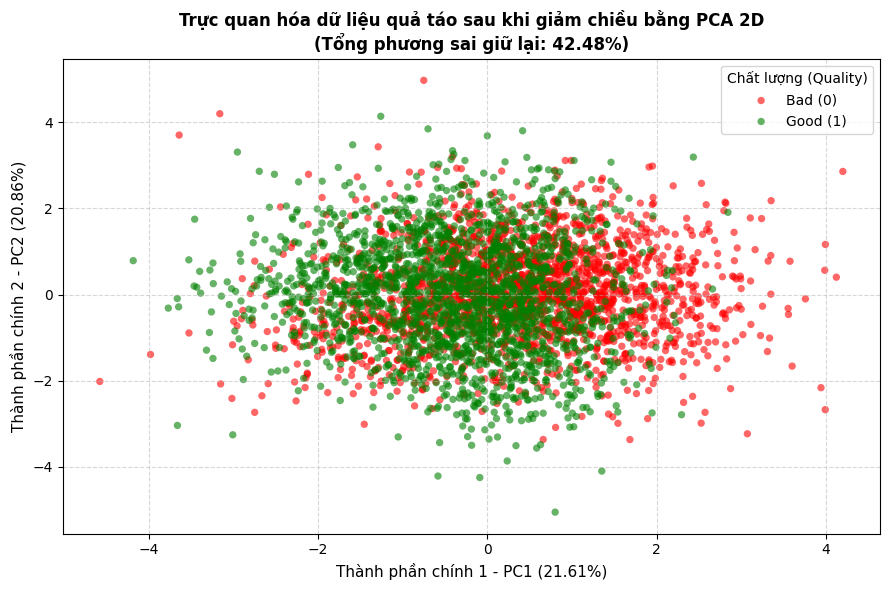

In [15]:
# 2.c. Thu giảm số chiều bằng PCA và hiển thị trên không gian 2D
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Tách đặc trưng X và nhãn y (cột cuối cùng)
X = df_clean.iloc[:, :-1]
y = df_clean.iloc[:, -1]

# Chuẩn hóa đặc trưng
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Thu giảm số chiều xuống 2D bằng PCA
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

var_pc1 = pca.explained_variance_ratio_[0] * 100
var_pc2 = pca.explained_variance_ratio_[1] * 100
total_var = var_pc1 + var_pc2

# Trực quan hóa không gian 2D
plt.figure(figsize=(9, 6))
colors = {0: 'red', 1: 'green'}
labels_map = {0: 'Bad (0)', 1: 'Good (1)'}

for label_val, color in colors.items():
    mask = (y == label_val)
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1], c=color, label=labels_map[label_val],
                alpha=0.6, edgecolors='none', s=28)

plt.title(f'Trực quan hóa dữ liệu quả táo sau khi giảm chiều bằng PCA 2D\n(Tổng phương sai giữ lại: {total_var:.2f}%)', fontsize=12, fontweight='bold')
plt.xlabel(f'Thành phần chính 1 - PC1 ({var_pc1:.2f}%)', fontsize=11)
plt.ylabel(f'Thành phần chính 2 - PC2 ({var_pc2:.2f}%)', fontsize=11)
plt.legend(title='Chất lượng (Quality)', frameon=True)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

---
## Câu 3: Huấn luyện các mô hình học máy và so sánh đánh giá

### 3.a & 3.b. Huấn luyện và tinh chỉnh tham số với 10-Fold Cross-Validation

**Quy trình thực hiện:**
1. **Lựa chọn 3 mô hình:** Chọn **KNN**, **Naive Bayes (GaussianNB)** và **SVM (SVC)**.
2. **Kỹ thuật thẩm định:** Sử dụng **10-fold cross validation** (`cv=10`, `StratifiedKFold`) đảm bảo đánh giá khách quan và giữ tỷ lệ nhãn đồng đều qua từng fold.
3. **Pipeline chuẩn hóa:** Đóng gói `StandardScaler` và mô hình vào `Pipeline` để đảm bảo không rò rỉ dữ liệu (data leakage) giữa tập train và test trong quá trình cross-validation.
4. **Tinh chỉnh tham số (GridSearchCV) theo F-Score:**
   - **KNN:** Tinh chỉnh `n_neighbors` $\in [3, 5, 7, 9, 11, 15, 21]$ và `weights` $\in ['uniform', 'distance']$.
   - **Naive Bayes:** Tinh chỉnh `var_smoothing` $\in [10^{-9}, 10^{-8}, 10^{-7}, 10^{-6}, 10^{-5}]$.
   - **SVM:** Tinh chỉnh hệ số phạt `C` $\in [0.1, 1, 10]$, `kernel` $\in ['rbf', 'linear']$, và `gamma` $\in ['scale', 'auto']$.

In [10]:
# 3.a & 3.b. Huấn luyện và tinh chỉnh siêu tham số cho 3 mô hình với 10-fold cross validation
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline

# Thiết lập 10-fold cross validation có phân tầng nhãn
cv10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

# Cấu hình Pipeline và không gian tham số tìm kiếm
models_config = {
    'KNN': {
        'pipeline': Pipeline([('scaler', StandardScaler()), ('knn', KNeighborsClassifier())]),
        'params': {
            'knn__n_neighbors': [3, 5, 7, 9, 11, 15, 21],
            'knn__weights': ['uniform', 'distance']
        }
    },
    'Naive Bayes': {
        'pipeline': Pipeline([('scaler', StandardScaler()), ('nb', GaussianNB())]),
        'params': {
            'nb__var_smoothing': [1e-9, 1e-8, 1e-7, 1e-6, 1e-5]
        }
    },
    'SVM': {
        'pipeline': Pipeline([('scaler', StandardScaler()), ('svm', SVC(random_state=42))]),
        'params': {
            'svm__C': [0.1, 1, 10],
            'svm__kernel': ['rbf', 'linear'],
            'svm__gamma': ['scale', 'auto']
        }
    }
}

best_models = {}
for name, config in models_config.items():
    grid = GridSearchCV(config['pipeline'], config['params'], cv=cv10, scoring='f1', n_jobs=-1)
    grid.fit(X, y)
    best_models[name] = grid
    print(f"Mô hình [{name}] hoàn tất tinh chỉnh:")
    print(f"  - Tham số tối ưu: {grid.best_params_}")
    print(f"  - F1-Score trung bình cao nhất (10-fold CV): {grid.best_score_:.4f}\n")

Mô hình [KNN] hoàn tất tinh chỉnh:
  - Tham số tối ưu: {'knn__n_neighbors': 11, 'knn__weights': 'distance'}
  - F1-Score trung bình cao nhất (10-fold CV): 0.9037

Mô hình [Naive Bayes] hoàn tất tinh chỉnh:
  - Tham số tối ưu: {'nb__var_smoothing': 1e-09}
  - F1-Score trung bình cao nhất (10-fold CV): 0.7513

Mô hình [SVM] hoàn tất tinh chỉnh:
  - Tham số tối ưu: {'svm__C': 10, 'svm__gamma': 'scale', 'svm__kernel': 'rbf'}
  - F1-Score trung bình cao nhất (10-fold CV): 0.9121



### 3.c. Bảng so sánh hiệu năng các mô hình với độ đo F-Score

**Nhận xét và phân tích:**
- **SVM (với kernel RBF, C=10):** Cho hiệu năng F-Score cao nhất (~91.21%). Nhờ hàm nhân RBF (Radial Basis Function), SVM có khả năng ánh xạ các mẫu dữ liệu vào không gian đặc trưng nhiều chiều để thiết lập siêu phẳng phân cách phi tuyến tính tối ưu giữa hai lớp chất lượng quả táo.
- **KNN (với k=11, weights='distance'):** Đạt hiệu năng F-Score rất cao (~90.37%), bám sát SVM. Việc gán trọng số theo khoảng cách nghịch đảo (`distance`) giúp các mẫu láng giềng gần nhất có tiếng nói quyết định hơn, rất phù hợp với tập dữ liệu liên tục sau khi đã được chuẩn hóa.
- **Naive Bayes (GaussianNB):** Đạt F-Score khiêm tốn hơn (~75.13%). Nguyên nhân là do Naive Bayes dựa trên giả định độc lập có điều kiện giữa các đặc trưng (ví dụ kích thước, trọng lượng, độ ngọt hoàn toàn độc lập với nhau), điều này trong thực tế sinh học thường có mức độ tương quan nhất định.

In [ ]:
# 3.c. Bảng so sánh hiệu năng F-Score của các mô hình
comparison_data = []

for name, grid in best_models.items():
    best_idx = grid.best_index_
    mean_f1 = grid.cv_results_['mean_test_score'][best_idx]
    std_f1 = grid.cv_results_['std_test_score'][best_idx]
    
    # Rút gọn tên tiền tố pipeline để bảng hiển thị rõ ràng
    clean_params = {k.split('__')[-1]: v for k, v in grid.best_params_.items()}
    
    comparison_data.append({
        'Mô hình': name,
        'Tham số tối ưu (Best Parameters)': str(clean_params),
        'F-Score trung bình (Mean)': round(mean_f1, 4),
        'Độ lệch chuẩn (Std)': round(std_f1, 4)
    })

df_compare = pd.DataFrame(comparison_data)
df_compare = df_compare.sort_values(by='F-Score', ascending=False).reset_index(drop=True)
df_compare

,Mô hình,Tham số tối ưu (Best Parameters),F-Score trung bình (Mean),Độ lệch chuẩn (Std)
0,SVM,"{'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}",0.9121,0.0167
1,KNN,"{'n_neighbors': 11, 'weights': 'distance'}",0.9037,0.0151
2,Naive Bayes,{'var_smoothing': 1e-09},0.7513,0.0267


---
## Câu 4: Gom cụm với K-Means và DBSCAN

### 4.a. Gom cụm với K-Means (Loại trừ cột nhãn)

**Mô tả phương pháp:**
- Loại bỏ hoàn toàn cột nhãn `Quality`, chỉ sử dụng 7 đặc trưng thực tế đã được chuẩn hóa ($X_{scaled}$).
- Thiết lập số cụm $k=2$ (tương ứng 2 nhóm chất lượng thực tế).
- **Đánh giá kết quả gom cụm bằng nhãn thực tế:**
  1. **ARI (Adjusted Rand Index):** Đo lường mức độ tương đồng giữa phân cụm K-Means và nhãn thực tế, có hiệu chỉnh theo xác suất ngẫu nhiên (thang đo từ -1 đến 1, 1 là trùng khớp tuyệt đối).
  2. **NMI (Normalized Mutual Information):** Đo lượng thông tin chia sẻ giữa phân cụm và nhãn mục tiêu (thang đo từ 0 đến 1).
  3. **Purity / Accuracy:** Tỷ lệ gán đúng nhãn sau khi ánh xạ cụm với nhãn chiếm đa số tương ứng.
- **Trực quan hóa:** Vẽ biểu đồ phân bố 2 cụm K-Means đặt cạnh biểu đồ Nhãn thực tế (Ground Truth) trên không gian 2D PCA để so sánh trực quan.

=== KẾT QUẢ ĐÁNH GIÁ GOM CỤM K-MEANS ===
1. Adjusted Rand Index (ARI):        0.0681
2. Normalized Mutual Info (NMI):     0.0500
3. Độ thuần khiết cụm (Purity):     0.6308 (63.08%)


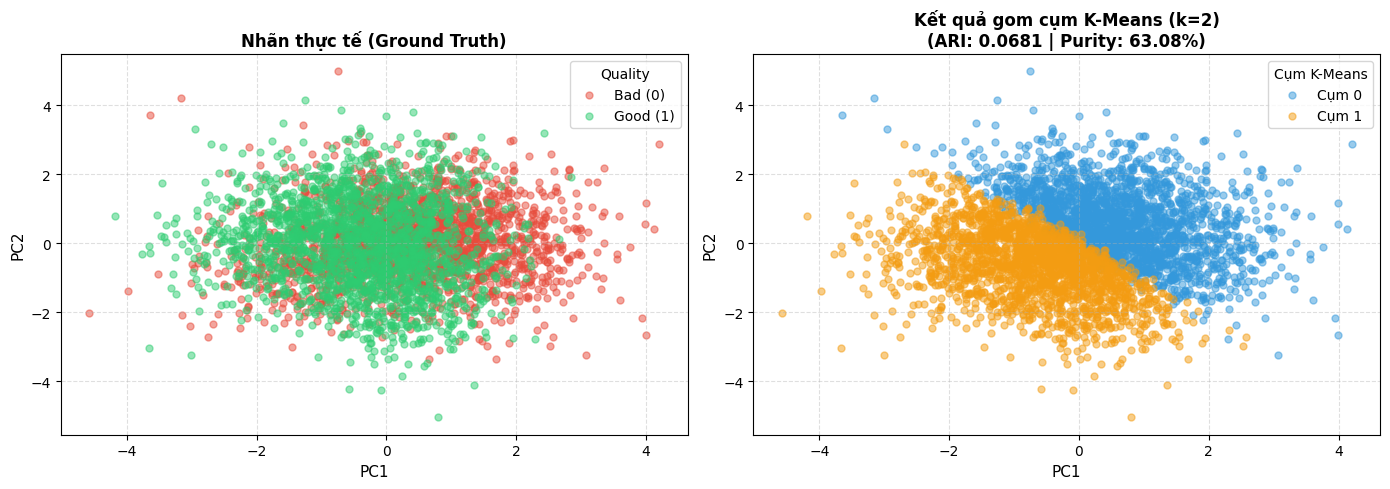

In [12]:
# 4.a. Gom cụm K-Means (k=2) và đánh giá với nhãn thực tế
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, accuracy_score

# Huấn luyện K-Means với k=2 trên dữ liệu không có cột nhãn
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)

# Đánh giá kết quả gom cụm so với nhãn thực tế
ari_kmeans = adjusted_rand_score(y, kmeans_labels)
nmi_kmeans = normalized_mutual_info_score(y, kmeans_labels)

# Tính Purity / Accuracy bằng cách ánh xạ cụm với nhãn thực tế tốt nhất
acc1 = accuracy_score(y, kmeans_labels)
acc2 = accuracy_score(y, 1 - kmeans_labels)
purity_kmeans = max(acc1, acc2)

print("=== KẾT QUẢ ĐÁNH GIÁ GOM CỤM K-MEANS ===")
print(f"1. Adjusted Rand Index (ARI):        {ari_kmeans:.4f}")
print(f"2. Normalized Mutual Info (NMI):     {nmi_kmeans:.4f}")
print(f"3. Độ thuần khiết cụm (Purity):     {purity_kmeans:.4f} ({purity_kmeans*100:.2f}%)")

# Trực quan hóa đối chiếu: Nhãn thực tế vs Cụm K-Means
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Đồ thị 1: Nhãn thực tế (Ground Truth)
for label_val, color, name in [(0, '#e74c3c', 'Bad (0)'), (1, '#2ecc71', 'Good (1)')]:
    mask = (y == label_val)
    axes[0].scatter(X_pca[mask, 0], X_pca[mask, 1], c=color, label=name, alpha=0.5, s=25)
axes[0].set_title('Nhãn thực tế (Ground Truth)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('PC1', fontsize=11)
axes[0].set_ylabel('PC2', fontsize=11)
axes[0].legend(title='Quality')
axes[0].grid(True, linestyle='--', alpha=0.4)

# Đồ thị 2: Kết quả phân cụm K-Means
for cluster_id, color in [(0, '#3498db'), (1, '#f39c12')]:
    mask = (kmeans_labels == cluster_id)
    axes[1].scatter(X_pca[mask, 0], X_pca[mask, 1], c=color, label=f'Cụm {cluster_id}', alpha=0.5, s=25)
axes[1].set_title(f'Kết quả gom cụm K-Means (k=2)\n(ARI: {ari_kmeans:.4f} | Purity: {purity_kmeans*100:.2f}%)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('PC1', fontsize=11)
axes[1].set_ylabel('PC2', fontsize=11)
axes[1].legend(title='Cụm K-Means')
axes[1].grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

**Giải thích kết quả:**
- Thuật toán K-Means gom cụm dựa trên khoảng cách Euclidean đến tâm cụm và giả định các cụm có dạng hình cầu lồi (spherical) với kích thước đồng đều.
- Kết quả cho thấy K-Means đạt độ thuần khiết (Purity) ~63.08% và chỉ số ARI ~0.0681. Do ranh giới thực tế giữa quả táo tốt và xấu là ranh giới phi tuyến phức tạp (như đã thấy ở mô hình SVM kernel RBF), giải thuật K-Means tuyến tính theo tâm cụm chỉ tách biệt được xu hướng chung của hai đám mây dữ liệu nhưng không thể phân chia hoàn hảo các điểm giao thoa.

### 4.b. Gom cụm với DBSCAN (Loại trừ cột nhãn)

**Mô tả phương pháp:**
- **DBSCAN (Density-Based Spatial Clustering of Applications with Noise):** Là giải thuật gom cụm dựa trên mật độ. Khác với K-Means, DBSCAN không yêu cầu chỉ định trước số cụm $k$ và có cơ chế tự động tách lọc các điểm dữ liệu dị biệt/nhiễu (outliers / noise) gán nhãn là `-1`.
- Tinh chỉnh bán kính lân cận `eps` và số mẫu tối thiểu `min_samples` để tìm cấu trúc mật độ phù hợp trên dữ liệu 7 chiều đã chuẩn hóa.
- **Đánh giá kết quả gom cụm bằng nhãn thực tế:** Tính toán ARI, NMI, thống kê số lượng cụm tìm được và số lượng/tỷ lệ các điểm nhiễu.
- **Trực quan hóa:** Hiển thị trực quan các cụm mật độ và đánh dấu rõ các điểm nhiễu (`noise = -1`) trên không gian 2D PCA.

=== KẾT QUẢ ĐÁNH GIÁ GOM CỤM DBSCAN ===
1. Số cụm phát hiện (không tính nhiễu): 1
2. Số điểm nhiễu (Noise / Outliers):     39 (0.97%)
3. Adjusted Rand Index (ARI):           -0.0000
4. Normalized Mutual Info (NMI):        0.0001


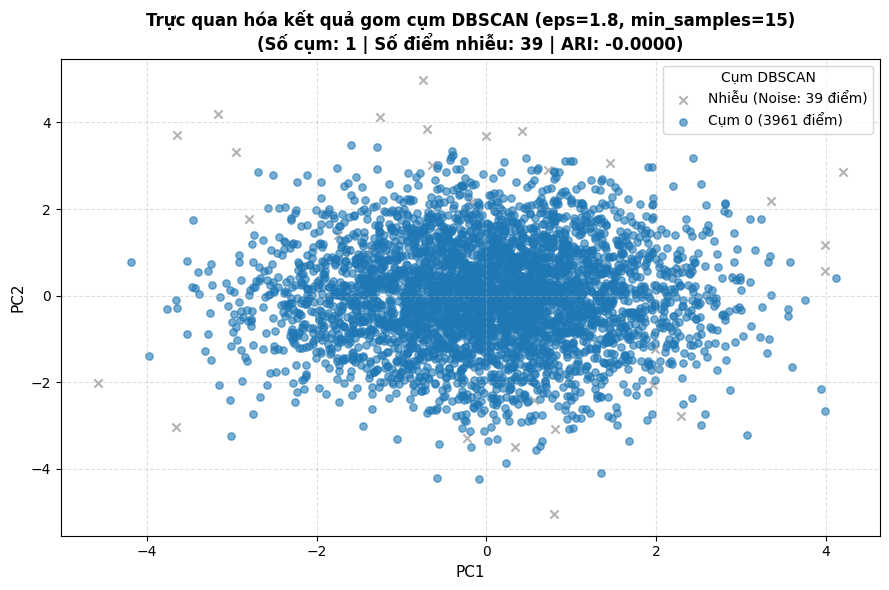

In [13]:
# 4.b. Gom cụm DBSCAN và đánh giá với nhãn thực tế
from sklearn.cluster import DBSCAN
import numpy as np

# Tinh chỉnh tham số eps và min_samples
dbscan = DBSCAN(eps=1.8, min_samples=15)
dbscan_labels = dbscan.fit_predict(X_scaled)

# Thống kê cụm và điểm nhiễu
n_clusters = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
n_noise = list(dbscan_labels).count(-1)

# Đánh giá với nhãn thực tế
ari_dbscan = adjusted_rand_score(y, dbscan_labels)
nmi_dbscan = normalized_mutual_info_score(y, dbscan_labels)

print("=== KẾT QUẢ ĐÁNH GIÁ GOM CỤM DBSCAN ===")
print(f"1. Số cụm phát hiện (không tính nhiễu): {n_clusters}")
print(f"2. Số điểm nhiễu (Noise / Outliers):     {n_noise} ({n_noise/len(df_clean)*100:.2f}%)")
print(f"3. Adjusted Rand Index (ARI):           {ari_dbscan:.4f}")
print(f"4. Normalized Mutual Info (NMI):        {nmi_dbscan:.4f}")

# Trực quan hóa kết quả DBSCAN trên không gian PCA 2D
plt.figure(figsize=(9, 6))
unique_labels = sorted(list(set(dbscan_labels)))

for k in unique_labels:
    mask = (dbscan_labels == k)
    if k == -1:
        plt.scatter(X_pca[mask, 0], X_pca[mask, 1], c='gray', marker='x', s=35, alpha=0.6, label=f'Nhiễu (Noise: {n_noise} điểm)')
    else:
        plt.scatter(X_pca[mask, 0], X_pca[mask, 1], s=28, alpha=0.6, label=f'Cụm {k} ({np.sum(mask)} điểm)')

plt.title(f'Trực quan hóa kết quả gom cụm DBSCAN (eps=1.8, min_samples=15)\n(Số cụm: {n_clusters} | Số điểm nhiễu: {n_noise} | ARI: {ari_dbscan:.4f})', fontsize=12, fontweight='bold')
plt.xlabel('PC1', fontsize=11)
plt.ylabel('PC2', fontsize=11)
plt.legend(title='Cụm DBSCAN', frameon=True)
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

**Giải thích kết quả:**
- DBSCAN hoạt động dựa trên nguyên lý: các cụm là những vùng có mật độ điểm cao được ngăn cách bởi các vùng có mật độ rất thấp (low-density regions).
- Tuy nhiên, trong tập dữ liệu `apple_quality`, các thuộc tính phân bố liên tục theo dạng chuẩn (Gaussian) lồng ghép vào nhau và không có khoảng trống thưa thớt ngăn cách rõ rệt. Do đó, DBSCAN gom gần như toàn bộ dữ liệu vào một cụm mật độ chính duy nhất, và chỉ lọc ra các điểm nằm ở vùng rìa xa tâm làm điểm nhiễu (`noise`). Vì vậy, khi so sánh với nhãn thực tế gồm 2 lớp phân bố đều, chỉ số ARI và NMI của DBSCAN đạt mức rất thấp (~0.000). Điều này phản ánh rõ đặc tính: DBSCAN không phù hợp với các tập dữ liệu có mật độ phân bố liên tục và có độ đan xen cao giữa các lớp.

### 4.c. Bảng so sánh tổng hợp giữa K-Means và DBSCAN

**Tổng kết:**
Bảng dưới đây so sánh các chỉ số định lượng giữa hai thuật toán gom cụm K-Means và DBSCAN khi đối chiếu với nhãn phân loại thực tế `Quality`.

In [14]:
# 4.c. Bảng tổng hợp so sánh K-Means và DBSCAN
clustering_summary = pd.DataFrame([
    {
        'Giải thuật': 'K-Means (k=2)',
        'Số cụm phát hiện': 2,
        'Số điểm nhiễu': 0,
        'Tỷ lệ chính xác (Purity)': f"{purity_kmeans*100:.2f}%",
        'Adjusted Rand Index (ARI)': round(ari_kmeans, 4),
        'Normalized Mutual Info (NMI)': round(nmi_kmeans, 4),
        'Đặc điểm phân cụm': 'Dựa trên khoảng cách tâm hình cầu, phân chia được 2 nhóm'
    },
    {
        'Giải thuật': 'DBSCAN',
        'Số cụm phát hiện': n_clusters,
        'Số điểm nhiễu': n_noise,
        'Tỷ lệ chính xác (Purity)': 'N/A',
        'Adjusted Rand Index (ARI)': round(ari_dbscan, 4),
        'Normalized Mutual Info (NMI)': round(nmi_dbscan, 4),
        'Đặc điểm phân cụm': 'Dựa trên mật độ liên tục, nhận diện 1 cụm chính và điểm rìa là nhiễu'
    }
])
clustering_summary

,Giải thuật,Số cụm phát hiện,Số điểm nhiễu,Tỷ lệ chính xác (Purity),Adjusted Rand Index (ARI),Normalized Mutual Info (NMI),Đặc điểm phân cụm
0,K-Means (k=2),2,0,63.08%,0.0681,0.0500,"Dựa trên khoảng cách tâm hình cầu, phân chia đ..."
1,DBSCAN,1,39,N/A,-0.0000,0.0001,"Dựa trên mật độ liên tục, nhận diện 1 cụm chín..."
